# Day 6 lab: Applied Lab 7 — BI case study implementation

<p class="lead">
Continue the EcoDrive Motors case from Lab 6. Forecast the cost of electric-vehicle batteries with Excel's Forecast Sheet, carry the worst-case forecast into a case-study dashboard that compares three sourcing strategies, and write a managerial report that weighs profit against ethical and social impact. This notebook gives the Excel steps and cross-checks the forecast in Python.
</p>

*Adapted from the DATA 300 syllabus, Applied Lab 7 (BI case study implementation). Instructions rewritten for this classroom; the data come bundled with the course.*

| | |
|---|---|
| **Graded** | Yes: **2%** of the course grade |
| **Outcomes** | CLO 4 and 5 |
| **Tools** | **Microsoft Excel** (Forecast Sheet; the graded work); this notebook in JupyterLab to check your forecast |
| **You submit** | Two files in the **Applied Lab 7** drop-box on **GAP (Moodle)**: your workbook `YourLastName_DATA300_Lab7.xlsx` and your report `YourLastName_Lab7_Report.pdf` |
| **Deadline** | **Wednesday 18 November, 23:59 China Standard Time**, unless your facilitator says otherwise (see the [schedule](schedule.md)) |

> **Three notes on the syllabus version**
>
> 1. **Eleven quarters, not twelve.** The history runs from Q1-2023 to Q3-2025: 11 values, in rows 2–12 (not 2–13).
> 2. **A numeric timeline.** Excel's Forecast Sheet needs the timeline to be numbers or dates at equal steps; labels such as "Q1-2023" are text. The bundled workbook therefore numbers the quarters 1–11 in column A and keeps the labels in column C.
> 3. **Five steps ahead.** From period 11 (Q3-2025), Q4-2026 is period **16**, five quarters ahead, so the forecast must end at 16.

---

## The business scenario

After your Lab 6 simulation, the EcoDrive Motors (**fictional**) board has a new worry. Shortages of lithium and cobalt have pushed the cost of EV batteries up and down over the last three years. Before committing to the 500-dollar **ethical sourcing premium** for next year's launch, the chief financial officer (CFO) wants to know where battery costs are heading, and what each sourcing strategy would earn if costs end up at the high end of the forecast.

Your three tasks:

1. **Predict:** forecast the battery cost per vehicle to Q4-2026 with Excel's exponential smoothing (ETS) forecast.
2. **Compare:** build a case-study dashboard of three sourcing strategies under the worst-case forecast cost.
3. **Recommend:** write a managerial report that weighs the money against the ethical and social impacts.

### Before you start

1. In the course folder, open **`data/ecodrive_battery_costs.xlsx`** in Excel and immediately **File → Save As** `YourLastName_DATA300_Lab7.xlsx` in your own folder. Its sheet **Historical Data** already holds the 11 quarters. (You may instead type the data into a blank workbook: same layout, sheet named *Historical Data*.)
2. Keep this notebook open next to Excel and run its cells with **Shift + Enter**.

The first cell loads the same data in Python.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY = "#c9c7c1"
INK = "#55534e"
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

history = pd.read_excel("data/ecodrive_battery_costs.xlsx", sheet_name="Historical Data", usecols="A:C")
print(history.to_string(index=False))

 Period  Battery Cost per EV ($) Quarter
      1                     7500 Q1-2023
      2                     7650 Q2-2023
      3                     7900 Q3-2023
      4                     8100 Q4-2023
      5                     8000 Q1-2024
      6                     8350 Q2-2024
      7                     8600 Q3-2024
      8                     8900 Q4-2024
      9                     8800 Q1-2025
     10                     9200 Q2-2025
     11                     9550 Q3-2025


---

## Part 1: Time series forecasting in Excel (CLO 4)

Excel's **Forecast Sheet** fits an **exponential smoothing (ETS)** model: it gives recent quarters more weight than old ones, follows the **trend**, and, if it finds one, a repeating **seasonal** pattern. It also draws a **95% confidence interval**: a lower and an upper bound around each forecast.

> **In Excel: create the forecast** (sheet *Historical Data*)
>
> 1. Check the layout: **A1** *Period*, **B1** *Battery Cost per EV ($)*, **C1** *Quarter*; periods 1–11 in **A2:A12**, costs in **B2:B12**. Format B2:B12 as currency if it is not already.
> 2. Select **A1:B12** (the timeline and the values, with their headers).
> 3. **Data → Forecast Sheet** (数据 → 预测工作表), in the *Forecast* group at the right of the Data tab.
> 4. In the preview window choose the **line chart**, then set **Forecast End** to **16** (period 16 = Q4-2026).
> 5. Click **Options** and check: *Confidence Interval* **95%**; *Seasonality* **Detect automatically**; *Timeline Range* `A2:A12`; *Values Range* `B2:B12`.
> 6. Click **Create**. Excel adds a new sheet with a table and a chart: the history, the **Forecast**, the **Lower Confidence Bound** and the **Upper Confidence Bound** for periods 12–16.
> 7. Rename the new sheet **Predictive Forecast**.
> 8. Find the row for period **16** (usually row 17) and write down three numbers for your report: the forecast, the lower bound and the upper bound. Note which cell holds the **upper bound** (usually **E17**); Part 2 links to it.

> **If Forecast Sheet is greyed out or missing**
>
> It needs Excel 2016 or later. Click a cell inside the data first. If Excel complains about the timeline, check that column A holds numbers 1–11 with no gaps and no text.

### Python cross-check

Excel chooses its ETS settings automatically, so its numbers depend on whether it detects a 4-quarter seasonal pattern. The cell below fits the two most likely versions with the same method (additive ETS) and prints their forecasts and 95% bounds. Your Excel results should be **close to one of the two**, but they will not match exactly: Excel's fitting procedure is not identical. In your report, quote **Excel's** numbers.

> **Predict, then reveal**
>
> Will the forecast for Q4-2026 be above or below 10,000 dollars? And the upper bound?

In [2]:
y = history["Battery Cost per EV ($)"].astype(float)
future_periods = np.arange(12, 17)                      # Q4-2025 ... Q4-2026
future_labels = ["Q4-2025", "Q1-2026", "Q2-2026", "Q3-2026", "Q4-2026"]

fits = {
    "trend only": ETSModel(y, error="add", trend="add").fit(disp=False),
    "trend + 4-quarter season": ETSModel(y, error="add", trend="add", seasonal="add",
                                         seasonal_periods=4).fit(disp=False),
}

forecasts = {}
for name, fit in fits.items():
    frame = fit.get_prediction(start=len(y), end=len(y) + 4).summary_frame(alpha=0.05)
    frame.index = pd.Index(future_periods, name="period")
    frame.insert(0, "quarter", future_labels)
    forecasts[name] = frame.rename(columns={"mean": "forecast", "pi_lower": "lower bound",
                                            "pi_upper": "upper bound"})
    print(f"--- ETS, {name} (US dollars per vehicle) ---")
    print(forecasts[name].to_string(formatters={c: "{:,.0f}".format
                                                for c in ["forecast", "lower bound", "upper bound"]}))
    print()

--- ETS, trend only (US dollars per vehicle) ---
        quarter forecast lower bound upper bound
period                                          
12      Q4-2025    9,578       9,356       9,801
13      Q1-2026    9,772       9,550       9,995
14      Q2-2026    9,966       9,744      10,189
15      Q3-2026   10,161       9,938      10,383
16      Q4-2026   10,355      10,132      10,577

--- ETS, trend + 4-quarter season (US dollars per vehicle) ---
        quarter forecast lower bound upper bound
period                                          
12      Q4-2025    9,800       9,672       9,927
13      Q1-2026    9,700       9,520       9,881
14      Q2-2026   10,000       9,779      10,221
15      Q3-2026   10,283      10,028      10,539
16      Q4-2026   10,533      10,247      10,818



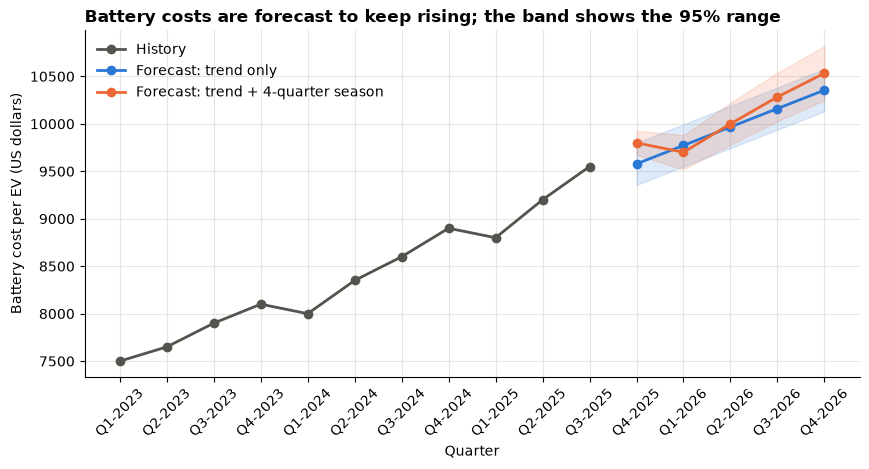

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(history["Period"], y, marker="o", color=INK, linewidth=2, label="History")
for (name, frame), colour in zip(forecasts.items(), [BLUE, ORANGE]):
    ax.plot(frame.index, frame["forecast"], marker="o", color=colour, linewidth=2, label=f"Forecast: {name}")
    ax.fill_between(frame.index, frame["lower bound"], frame["upper bound"], color=colour, alpha=0.15)
ax.set_xticks(range(1, 17), list(history["Quarter"]) + future_labels, rotation=45)
ax.set_title("Battery costs are forecast to keep rising; the band shows the 95% range")
ax.set_xlabel("Quarter")
ax.set_ylabel("Battery cost per EV (US dollars)")
ax.legend(frameon=False, loc="upper left")
plt.show()

Read the chart above: the line continues the upward trend, and the shaded band is the range in which the model expects the true cost to fall 95% of the time. Your Excel chart should look similar. Use your **Excel** Predictive Forecast sheet for questions 1 and 2.

---

## Part 2: The case-study dashboard

The CFO wants to plan for the **worst case** the forecast considers plausible: the **upper** confidence bound for Q4-2026. Three sourcing strategies are on the table:

| Strategy | Ethical premium per vehicle |
|---|---|
| 1. Profit-maximised (no ethical sourcing) | 0 |
| 2. Hybrid sourcing (half the batteries certified) | 250 |
| 3. Fully ethical (all batteries certified) | 500 |

> **In Excel: constants and the forecast link** (sheet *Case Study Dashboard*)
>
> 1. Add a sheet and rename it **Case Study Dashboard**.
> 2. Type the constants:
>
> | Cell | Label (column A) | Value (column B) |
> |---|---|---|
> | A1 / B1 | Expected EV Demand | 15000 |
> | A2 / B2 | EV Sale Price | 35000 |
> | A3 / B3 | Non-Battery Manufacturing Cost | 18000 |
> | A4 / B4 | Fixed Overhead Costs | 50000000 |
>
> 3. In **A6** type *Projected Battery Cost (Upper Confidence Bound, Q4-2026)*.
> 4. In **B6** type `=`, click the **Predictive Forecast** tab, click the cell with the **upper bound for period 16**, and press **Enter**. B6 now shows a formula such as `='Predictive Forecast'!E17`. Check that the value is the number you wrote down in Part 1.

> **In Excel: compare the three strategies**
>
> 1. Row 8, headings: **A8** *Strategy*, **B8** *1. Profit-Maximized (No Ethics)*, **C8** *2. Hybrid Sourcing (50% Ethical)*, **D8** *3. Fully Ethical (100% Certified)*.
> 2. Row 9, premium: **A9** *Ethical Premium*; **B9** `0`, **C9** `250`, **D9** `500`.
> 3. Row 10, cost per vehicle: **A10** *Total Variable Cost*; in **B10** type `=$B$3+$B$6+B9` and copy it to **C10:D10**. The `$` signs keep the non-battery cost and the battery cost fixed while the premium column changes.
> 4. Row 11, profit: **A11** *Projected Net Profit*; in **B11** type `=($B$1*$B$2)-($B$1*B10)-$B$4` and copy it to **C11:D11**.
> 5. Format **B9:D11** as currency.
> 6. *Recommended:* select **B8:D8**, hold **Ctrl** and select **B11:D11**, then **Insert → Column Chart** (插入 → 柱形图). Give the chart a message title, for example the profit gap between strategies 1 and 3.

The cell below computes the dashboard with each Python upper bound, so you can check your formulas. Your row 11 will differ a little, because your B6 comes from Excel's forecast; the **gaps between strategies** must match exactly. Work out why.

In [4]:
DEMAND, PRICE, NON_BATTERY, OVERHEAD = 15_000, 35_000, 18_000, 50_000_000
PREMIUMS = {"1. Profit-Maximized (No Ethics)": 0,
            "2. Hybrid Sourcing (50% Ethical)": 250,
            "3. Fully Ethical (100% Certified)": 500}


def dashboard(battery_cost):
    """Rows 9-11 of the Case Study Dashboard for a given battery cost per vehicle (cell B6)."""
    rows = {}
    for strategy, premium in PREMIUMS.items():
        variable = NON_BATTERY + battery_cost + premium
        rows[strategy.split(" (")[0]] = {"premium (row 9)": premium, "variable cost (row 10)": variable,
                                         "net profit (row 11)": DEMAND * PRICE - DEMAND * variable - OVERHEAD}
    return pd.DataFrame(rows).T


for name, frame in forecasts.items():
    upper = frame.loc[16, "upper bound"]
    print(f"--- B6 = {upper:,.0f} (upper bound for Q4-2026, ETS {name}) ---")
    print(dashboard(upper).map("{:,.0f}".format).to_string())
    print()

--- B6 = 10,577 (upper bound for Q4-2026, ETS trend only) ---
                    premium (row 9) variable cost (row 10) net profit (row 11)
1. Profit-Maximized               0                 28,577          46,343,926
2. Hybrid Sourcing              250                 28,827          42,593,926
3. Fully Ethical                500                 29,077          38,843,926

--- B6 = 10,818 (upper bound for Q4-2026, ETS trend + 4-quarter season) ---
                    premium (row 9) variable cost (row 10) net profit (row 11)
1. Profit-Maximized               0                 28,818          42,722,534
2. Hybrid Sourcing              250                 29,068          38,972,534
3. Fully Ethical                500                 29,318          35,222,534



---

## Part 3: Managerial report

Write a short, professional **managerial report** in Word for the CFO and the board. Use the two section headings below, put your name and student ID at the top, and answer every question in complete sentences, quoting **your Excel numbers** with units. You may paste your forecast chart and dashboard into the report as pictures (copy them from Excel).

### Section 1: Predictive modelling analysis (CLO 4)

| # | Question |
|---|---|
| **1** | **Trend.** Describe the history of battery costs shown on your Predictive Forecast sheet: direction, rough size of the change, and any repeating pattern within the year. What is the **forecast** (baseline) battery cost for Q4-2026? |
| **2** | **Confidence intervals.** Explain, in your own words, what the lower and upper confidence bounds mean in a forecast. Why does the dashboard use the **upper** bound rather than the baseline forecast? |

### Section 2: Ethical impact and BI evaluation (CLO 5)

| # | Question |
|---|---|
| **3** | **The cost of ethics.** If the worst-case battery cost for Q4-2026 comes true, what is the projected net profit of Strategy 1 (no ethics) and of Strategy 3 (fully ethical)? How large is the difference, in dollars and as a share of Strategy 1's profit? |
| **4** | **Recommendation.** EcoDrive markets itself as a "green and responsible" company, yet full ethical sourcing plus rising battery costs cuts its margins. As an analytics consultant, write **one or two paragraphs** recommending **one** of the three strategies. Justify it by weighing the numbers (profit, costs) against the societal impacts: brand reputation, human rights in the supply chain, and corporate social responsibility. |
| **5** | **The value of BI.** Why does combining a time series forecast with a dashboard of several strategies support a better decision than simply looking at last year's battery costs? |

> **Writing tips**
>
> Start Section 2 with your recommendation in one sentence. Quote the profit gap in dollars **and** in per cent. A strong recommendation names what the spreadsheet leaves out (fines, import bans on goods linked to forced labour, boycotts, staff and investor reactions) and says what you would monitor after the decision. "Hybrid" is not automatically the safe middle: if you choose it, explain what happens to the uncertified half.

---

## Part 4: Save and submit

1. Check the workbook has the sheets **Historical Data**, **Predictive Forecast** and **Case Study Dashboard**, and that B6 on the dashboard is a **link** to the forecast sheet (click it: the formula bar shows `='Predictive Forecast'!…`).
2. Save it as **`YourLastName_DATA300_Lab7.xlsx`**.
3. Save the report as PDF: **File → Save As → PDF** (文件 → 另存为 → PDF), named **`YourLastName_Lab7_Report.pdf`**.
4. Log in to **GAP (Moodle)**, open the **DATA 300: Applied Lab 7** drop-box, upload **both** files and click **Submit** by **23:59 China Standard Time today**.

Paste any charts into the Word report before you save it as PDF, so the report is a single file. If you end up with two PDFs, combine them as shown in [Combining PDFs without internet](setup.md#combining-pdfs-without-internet).

---

## Checklist before you upload

- [ ] Predictive Forecast sheet created by Forecast Sheet, ending at period 16, with lower and upper bounds.
- [ ] Case Study Dashboard: B6 links to the period-16 upper bound; rows 9–11 complete and formatted as currency.
- [ ] The gaps between strategies match the Part 2 check.
- [ ] Report: two sections, five numbered answers, Excel numbers quoted with units, one clear recommendation.
- [ ] Files named `YourLastName_DATA300_Lab7.xlsx` and `YourLastName_Lab7_Report.pdf`, both uploaded to the Applied Lab 7 drop-box on GAP (Moodle).

## How it is marked

The lab uses the course's Lab 7 rubric: **CLO 4** (developing predictive models such as time series forecasts to project outcomes, 40 points), **CLO 5** (evaluating BI tools in a case and writing managerial reports that consider ethical and societal contexts, 40 points), **professional formatting** (10 points) and **clear academic writing** (10 points). In practice: a working forecast and dashboard linked by formula, a correct reading of the confidence bounds, profit figures quoted correctly, and a recommendation that weighs money and ethics instead of mentioning ethics in passing.

---

## Going further (not graded)

The dashboard uses one battery cost. A **one-way Data Table** shows how the three profits respond to any battery cost. Because a Data Table's input cell must be on its own sheet, build it on the **Case Study Dashboard** itself, where B6 lives:

1. In **F2:F8** type battery costs from 9,000 to 12,000 in steps of 500 (down a column).
2. In **G1**, **H1**, **I1** type `=B11`, `=C11`, `=D11` (one row above the first cost, one column to the right).
3. Select **F1:I8**, then **Data → What-If Analysis → Data Table**, leave *Row input cell* empty, set *Column input cell* to `B6`, and click **OK**.

The table temporarily replaces B6 with each cost. The cell below draws the same thing in Python and prints the battery cost at which each strategy would stop making a profit.

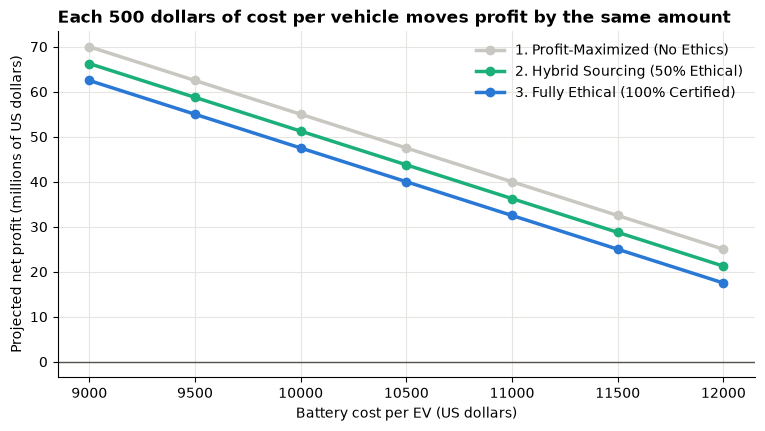

1. Profit-Maximized (No Ethics)      breaks even at a battery cost of 13,667 dollars per vehicle
2. Hybrid Sourcing (50% Ethical)     breaks even at a battery cost of 13,417 dollars per vehicle
3. Fully Ethical (100% Certified)    breaks even at a battery cost of 13,167 dollars per vehicle


In [5]:
battery_costs = np.arange(9_000, 12_001, 500)
fig, ax = plt.subplots()
for (strategy, premium), colour in zip(PREMIUMS.items(), [GREY, AQUA, BLUE]):
    profits = DEMAND * (PRICE - NON_BATTERY - battery_costs - premium) - OVERHEAD
    ax.plot(battery_costs, profits / 1e6, marker="o", color=colour, linewidth=2.5, label=strategy)
ax.axhline(0, color=INK, linewidth=1)
ax.set_title("Each 500 dollars of cost per vehicle moves profit by the same amount")
ax.set_xlabel("Battery cost per EV (US dollars)")
ax.set_ylabel("Projected net profit (millions of US dollars)")
ax.legend(frameon=False)
plt.show()

for strategy, premium in PREMIUMS.items():
    print(f"{strategy:<36} breaks even at a battery cost of "
          f"{PRICE - NON_BATTERY - premium - OVERHEAD / DEMAND:,.0f} dollars per vehicle")

> **Stuck?**
>
> *No Forecast Sheet button:* you need Excel 2016 or later; ask your facilitator for a lab PC. *Excel rejects the timeline:* column A must hold the numbers 1–11, not the quarter labels. *B6 shows 0 or `#REF!`:* the link points at an empty cell or a deleted sheet; re-create it by typing `=` and clicking the upper bound for period 16. *`FileNotFoundError` in this notebook:* keep the notebook in the course folder, next to the `data` folder. For anything else, take a screenshot and ask your facilitator.